# 01 · Dados, sessões e vazamento
Dados reais (Sudars, milho Nigéria, DeepWeeds). Tudo aqui é recalculado a partir dos arquivos em `data/`.

In [1]:
import sys, json, glob, pickle
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, matplotlib
matplotlib.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt


## 1. Sudars: tamanho dos objetos e classes

{
 "train": {
  "imagens": 650,
  "sessoes": 3,
  "weed": 4462,
  "crop": 3
 },
 "val": {
  "imagens": 151,
  "sessoes": 1,
  "weed": 1127,
  "crop": 0
 },
 "test": {
  "imagens": 134,
  "sessoes": 6,
  "weed": 452,
  "crop": 4
 },
 "test_origin": {
  "imagens": 241,
  "sessoes": 1,
  "weed": 1401,
  "crop": 403
 }
}
descartes: {'caixas_degeneradas': 1, 'sem_imagem': 0, 'classe_desconhecida': 0}


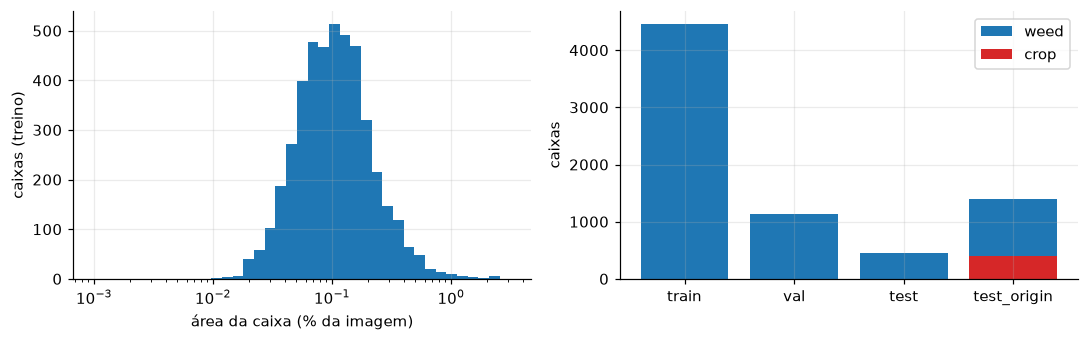

mediana 0.103% | p90 0.260% | <0,5%: 98%


In [2]:
man = json.load(open(ROOT/"data/processed/sudars_yolo/manifest.json"))
items, info = man["items"], man["info"]
print(json.dumps(info["stats"], indent=1, ensure_ascii=False)); print("descartes:", info["descartes"])
areas = []
for f in glob.glob(str(ROOT/"data/processed/sudars_weed/labels/train/*.txt")):
    for l in open(f): areas.append(float(l.split()[3])*float(l.split()[4]))
areas = np.array(areas)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(areas*100, bins=np.logspace(-3, 0.5, 40)); ax[0].set_xscale("log"); ax[0].set_xlabel("área da caixa (% da imagem)"); ax[0].set_ylabel("caixas (treino)")
ax[1].bar(["train","val","test","test_origin"], [info["stats"][k]["weed"] for k in ("train","val","test","test_origin")], label="weed")
ax[1].bar(["train","val","test","test_origin"], [info["stats"][k]["crop"] for k in ("train","val","test","test_origin")], label="crop", color="C3"); ax[1].legend(); ax[1].set_ylabel("caixas")
plt.tight_layout(); plt.show()
print("mediana %.3f%% | p90 %.3f%% | <0,5%%: %.0f%%" % (np.median(areas)*100, np.percentile(areas, 90)*100, 100*(areas<.005).mean()))

**Leitura:** objetos minúsculos (mediana ≈ 0,1% da imagem; 98% < 0,5%) e `crop` quase só em `test_origin` (403 de 411 caixas; treino: 3). Por isso o detector é de **uma classe** e `crop` não tem métrica.

## 2. A suposição de sessão: vizinhos de ID são mais parecidos?
Correlação de miniaturas (32×18, cinza) entre imagens com IDs consecutivos vs. pares aleatórios.

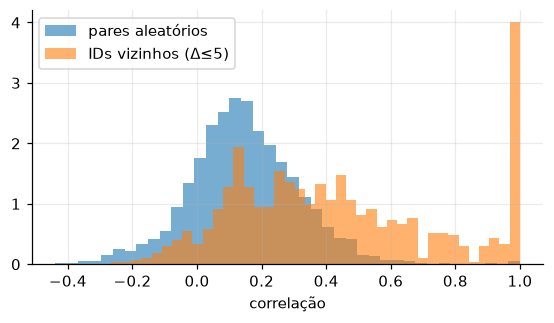

mediana vizinhos 0.38 vs aleatórios 0.14 (n=859 vs 2995)


In [3]:
import re, cv2
base = ROOT/"data/raw/sudars/ex/Ronin_OPEN_DB/raw images"
num = sorted((int(p.stem), p) for p in base.glob("*.jpg") if re.fullmatch(r"\d+", p.stem))
thumb = lambda p: cv2.resize(cv2.imread(str(p), 0), (32, 18), interpolation=cv2.INTER_AREA).astype(float).ravel()
T = np.array([thumb(p) for _, p in num]); T = (T - T.mean(1, keepdims=True)) / T.std(1, keepdims=True)
ids = np.array([i for i, _ in num])
nb = np.array([(T[k]*T[k+1]).mean() for k in range(len(T)-1) if ids[k+1]-ids[k] <= 5])
rng = np.random.default_rng(0); a, b = rng.integers(0, len(T), 3000), rng.integers(0, len(T), 3000)
rd = np.array([(T[i]*T[j]).mean() for i, j in zip(a, b) if i != j])
plt.figure(figsize=(6, 3)); plt.hist(rd, 40, alpha=.6, label="pares aleatórios", density=True); plt.hist(nb, 40, alpha=.6, label="IDs vizinhos (Δ≤5)", density=True); plt.legend(); plt.xlabel("correlação"); plt.show()
print("mediana vizinhos %.2f vs aleatórios %.2f (n=%d vs %d)" % (np.median(nb), np.median(rd), len(nb), len(rd)))

**Leitura:** imagens com IDs vizinhos são bem mais parecidas (correlação mediana 0,38) que pares aleatórios (0,14). Isso **sustenta, mas não prova**, que IDs contíguos são capturas da mesma sessão; é a base da suposição de sessão. Não há metadado real de fazenda/data.

## 3. DeepWeeds: por que split por data, e por que não dá para ter validação

In [4]:
from weedvision import deepweeds as D
from collections import defaultdict
rows = D.read_labels(ROOT/"data/raw/deepweeds/labels.csv")
days = defaultdict(set)
for r in rows: days[D.CLASSES[r["label"]]].add(r["date"])
print("dias distintos por classe:", {k: len(v) for k, v in days.items()}, "| negativos: %.0f%%" % (100*sum(r["label"]==8 for r in rows)/len(rows)))
for kind, fn in (("aleatório", D.split_random), ("por data", D.split_date)):
    sp = fn(rows); print(kind, D.leakage_report(rows, sp))

dias distintos por classe: {'Chinee apple': 22, 'Lantana': 14, 'Negative': 34, 'Snake weed': 20, 'Siam weed': 3, 'Prickly acacia': 6, 'Parthenium': 3, 'Rubber vine': 6, 'Parkinsonia': 2} | negativos: 52%
aleatório {'dias_total': 60, 'dias_em_mais_de_um_split': 60, 'imagens': {'train': 12252, 'val': 2626, 'test': 2631}}


por data {'dias_total': 60, 'dias_em_mais_de_um_split': 0, 'imagens': {'train': 12254, 'test': 5255}}


**Leitura:** com split aleatório **60 de 60 dias** aparecem em mais de um split (vazamento de sessão). Com split por dia, 0. *Parkinsonia* existe em só 2 dias, *Parthenium* e *Siam weed* em 3 — por isso o split por data só pode ter treino/teste (não há como ter as 9 classes nos 3 splits). 52% das imagens são negativas.